# Does forgetting get *worse* for facts the model sees more often?

**Purpose of this notebook.** An earlier premise of this project was that *frequently
attested facts are forgotten more*. That would contradict the three papers closest to this
setting — Kandpal et al. (2023), Mallen et al. (2023) and Chang et al. (2024), all of which
find frequency **helps** recall and durability. This notebook tests the premise on the LMEnt
13-checkpoint panel and shows the answer flips depending on **which statistic you compute**:
forgetting *counts* rise with frequency, the forgetting *hazard* falls.

### The distinction that decides it

A fact can only be *observed* to be forgotten at a checkpoint where it is currently correct,
so there are two different quantities:

|  | definition | what it confounds |
|---|---|---|
| **forgetting count**  | how many times a fact went correct → wrong | how *often it was correct at all* |
| **forgetting hazard** | P(wrong at $t{+}1$ \| correct at $t$) | nothing — it is normalised by opportunity |

### Two notions of "frequency"

- `num_shared_chunks` — training chunks where the subject and the answer co-occur: **evidence for this specific fact**.
- `total_subj_chunks` — training chunks mentioning the subject at all: **how famous the entity is**.

> *Scope note.* This dataset is the **top-10 % exposure slice** of PopQA-KAS, so even the
> lowest quintile has ≈ 42 supporting chunks. The genuine long tail Kandpal et al. study is
> not sampled here; every statement below is about variation *within* a well-attested set.

## The data this notebook consumes, and how to regenerate it

Nothing here touches a GPU — the notebook only reads artifacts written by an earlier
evaluation sweep. All three inputs are **versioned in the repo**.

| # | Path (relative to the repo root) | What it holds | Used for |
|---|---|---|---|
| **1** | `data/artifacts/recall/rotemab_15shot_top10_internal/recall_step{S}_15shot_top10pct.parquet` | 13 parquets, one per checkpoint (`50 000 … 658 032`); 1 452 rows × 34 columns — `correct`, `excluded`, `is_top1`, `gold_prob` and the other output scalars | the fact × checkpoint recall panel |
| **2** | `15_shot_top_10_trajectory_with_fact_properites.csv` | per-fact `prop` (relation) and `num_shared_chunks` (evidence for the fact) | the evidence-frequency feature |
| **3** | `competition_df.parquet` | one row per PopQA-KAS fact (14 267): `total_subj_chunks`, `chunks_ratio`, `num_competitive_facts`, `competitive_word` | the subject-popularity feature |

**Input 1 — regenerate with one GPU sweep.** 13 checkpoints of `dhgottesman/LMEnt-1B-6E`,
scoring the same 1 452 facts (the top decile of `popqa-kas` by `num_shared_chunks`), of which
1 310 survive the `excluded` filter:

```bash
pip install -r requirements.txt
export LMENT_DATA_ROOT=/path/to/storage        # checkpoints, corpus, artifacts land here
STEPS="50000 100000 150000 200000 250000 300000 350000 400000 450000 500000 550000 600000 658032"

python feature_extraction/eval_checkpoints.py --num-shots 15 --no-hidden \
    --steps $STEPS --top-shared-chunks-pct 10 \
    --output-dir $LMENT_DATA_ROOT/artifacts/recall/rotemab_15shot_top10_internal
```

`--no-hidden` keeps only the recall parquets (no residual-stream dump). The run is one forward
sweep per checkpoint and is safely restartable — an existing `recall_step{S}…parquet` is
skipped — so the natural shape is a 13-task Slurm array, one checkpoint per task.

**Input 2** comes from `trajectory_analysis_rotemab_15shot_top10.ipynb`, which pivots a recall
run into a trajectory table and merges the fact properties. This notebook reads only two of its
columns, so the minimal equivalent is:

```python
from datasets import load_dataset
qa = load_dataset("dhgottesman/popqa-kas")["train"].to_pandas()
qa[["id", "prop", "subject_num_chunks", "answer_num_chunks", "num_shared_chunks"]] \
  .to_csv("15_shot_top_10_trajectory_with_fact_properites.csv", index=False)
```

**Input 3** is a checked-in corpus-index artifact — it is committed to the repo and no script
here regenerates it. `total_subj_chunks` counts the chunks containing the subject's key
("competitive") token; `chunks_ratio` is `num_shared_chunks / total_subj_chunks`.

### Two things that will bite on a fresh checkout

- **`--steps` is not optional.** `config.CHECKPOINT_STEPS` still lists the 1-epoch schedule; the
  13 checkpoints analysed here belong to the **6-epoch** model (`config.MODEL_ID =
  dhgottesman/LMEnt-1B-6E`, `TOTAL_STEPS = 658032`) and must be passed explicitly.
- **Directory layout.** `--output-dir D` writes `D/recall/` and `D/internal/`, but input 1 is
  read here as a *flat* directory of parquets, as it is arranged locally. Keep the flat form, or
  point `TRAJ_DIR` one level deeper.

---
## 1 — The fact × checkpoint recall panel, plus the frequency features

13 checkpoints (50 k → 658 032 steps) of 15-shot recall over 1 452 PopQA-KAS facts. Facts whose
answer leaks into the few-shot prompt are marked `excluded` and dropped — that is a property of
the *fact*, so the surviving set is identical at every checkpoint and the panel stays balanced.

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# --- visual style, shared with the other notebooks in this project ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated pair (OKLab dE 33.6 normal, 24.7 CVD)
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def clean(ax):
    """Recessive axes: horizontal grid only, no spines, no ticks."""
    ax.grid(axis="y", alpha=.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

In [2]:
TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]

# --- fact x checkpoint matrices -------------------------------------------------
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step", "correct", "is_top1", "gold_prob"]])
long = pd.concat(frames, ignore_index=True)

def panel(col):
    return long.pivot(index="id", columns="step", values=col).reindex(columns=steps)

correct   = panel("correct").to_numpy().astype(bool)     # (n_facts, n_steps)
is_top1   = panel("is_top1").to_numpy().astype(bool)
gold_prob = panel("gold_prob").to_numpy(float)
ids       = panel("correct").index
n_facts, n_steps = correct.shape

print(f"{n_facts} scoreable facts x {n_steps} checkpoints "
      f"({steps[0]//1000}k -> {steps[-1]//1000}k steps)")
print(f"accuracy {correct[:, 0].mean():.1%} -> {correct[:, -1].mean():.1%}")

1310 scoreable facts x 13 checkpoints (50k -> 658k steps)
accuracy 14.4% -> 41.5%


In [3]:
# --- frequency features, aligned row-for-row to the panel -----------------------
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id")
comp  = pd.read_parquet("competition_df.parquet").set_index("id")   # subject-level counts

evidence = props["num_shared_chunks"].reindex(ids).to_numpy(float)  # chunks stating the fact
subj_pop = comp["total_subj_chunks"].reindex(ids).to_numpy(float)   # chunks mentioning the subject

FREQ = [("num_shared_chunks\n(evidence for the fact)", evidence),
        ("total_subj_chunks\n(subject popularity)",    subj_pop)]

print(f"missing values: evidence {np.isnan(evidence).sum()}, subject popularity {np.isnan(subj_pop).sum()}")
print(f"evidence      : min {np.nanmin(evidence):.0f}   median {np.nanmedian(evidence):.0f}   max {np.nanmax(evidence):.0f}")
print(f"subject pop.  : min {np.nanmin(subj_pop):.0f}   median {np.nanmedian(subj_pop):.0f}   max {np.nanmax(subj_pop):.0f}")
print(f"log-scale correlation between the two: "
      f"{spearmanr(np.log1p(evidence), np.log1p(subj_pop))[0]:+.2f}")

missing values: evidence 0, subject popularity 0
evidence      : min 42   median 170   max 101081
subject pop.  : min 46   median 10618   max 1411614
log-scale correlation between the two: +0.34


### The two statistics, defined once

Everything below is built from two aligned boolean matrices over the 12 checkpoint-to-checkpoint
transitions:

- `at_risk[i, t]` — fact *i* is correct at checkpoint *t* (an **opportunity** to forget),
- `forgot[i, t]` — it is correct at *t* and wrong at *t + 1* (an **event**),

and the hazard for any group is `events.sum() / opportunities.sum()`.

Two groupings are used, and it matters which is which:

- **fact quintiles** (§§2–3) — each bin holds the same number of *facts*, which is what lets
  events and opportunities be compared per fact.
- **transition quintiles** — each bin holds the same number of *at-risk observations*. Rates need
  this one, since low-evidence facts contribute very few transitions.

In [4]:
at_risk = correct[:, :-1]                       # correct now  -> could be forgotten next
forgot  = correct[:, :-1] & ~correct[:, 1:]     # correct now, wrong next

n_opp, n_ev = at_risk.sum(), forgot.sum()
BASE = n_ev / n_opp
print(f"{n_opp} correct->next transitions, {n_ev} of them forgetting events")
print(f"overall forgetting hazard: {BASE:.1%}")

# Transition-level view: one row per (fact, checkpoint) at which the fact is correct.
f_idx, t_idx = np.where(at_risk)
t_forgot   = forgot[f_idx, t_idx]
t_goldprob = gold_prob[f_idx, t_idx]
t_top1     = is_top1[f_idx, t_idx]


def by_fact_quintile(values, n_bins=5):
    """Equal-sized bins of *facts*; events and opportunities pooled within each bin."""
    q = pd.qcut(values, n_bins, labels=False, duplicates="drop")
    rows = []
    for b in range(int(np.nanmax(q)) + 1):
        m = q == b
        rows.append({
            "quintile":           b + 1,
            "median freq":        np.median(values[m]),
            "facts":              int(m.sum()),
            "events/fact":        forgot[m].sum(1).mean(),
            "correct ckpts/fact": at_risk[m].sum(1).mean(),
            "opportunities":      int(at_risk[m].sum()),
            "events":             int(forgot[m].sum()),
            "hazard":             forgot[m].sum() / max(at_risk[m].sum(), 1),
        })
    return pd.DataFrame(rows)


def by_transition_quintile(values, keep=None, n_bins=5, min_n=30):
    """Equal-sized bins of *at-risk transitions*, binned on the fact-level `values`.

    Bin edges are always computed on all transitions, so a restricted subset
    (`keep`, a boolean mask over transitions) stays comparable to the full curve.
    Bins with fewer than `min_n` surviving observations report NaN rather than a
    rate estimated from a handful of points.
    """
    v = values[f_idx]
    q = pd.qcut(v, n_bins, labels=False, duplicates="drop").astype(int)
    k = np.ones(v.shape, bool) if keep is None else keep
    rows = []
    for b in range(q.max() + 1):
        m = (q == b) & k
        rows.append({"quintile": b + 1, "median freq": np.median(v[q == b]), "n": int(m.sum()),
                     "hazard": t_forgot[m].mean() if m.sum() >= min_n else np.nan})
    return pd.DataFrame(rows)

4154 correct->next transitions, 1003 of them forgetting events
overall forgetting hazard: 24.1%


---
## 2 — Reproducing the claim: forgetting **counts** do rise with frequency

Reproduce LMEnt observations - forgetting rate rises with frequency rate.

**Figure — forgetting events per fact rise 3.5× with evidence.** Facts are sorted by
`num_shared_chunks` and cut into five **equal-sized bins** (≈ 262 facts each); each bar is the
mean number of forgetting events per fact in its bin.

*Reading the x axis.* Each bin is labelled by the **median `num_shared_chunks` of the facts
inside it** — 50, 80, 170, 506, 3 628. The bins are equally *populated*, not equally *wide*, so
the axis is monotone but far from linear: the top bin sits ≈ 70× higher than the bottom one.

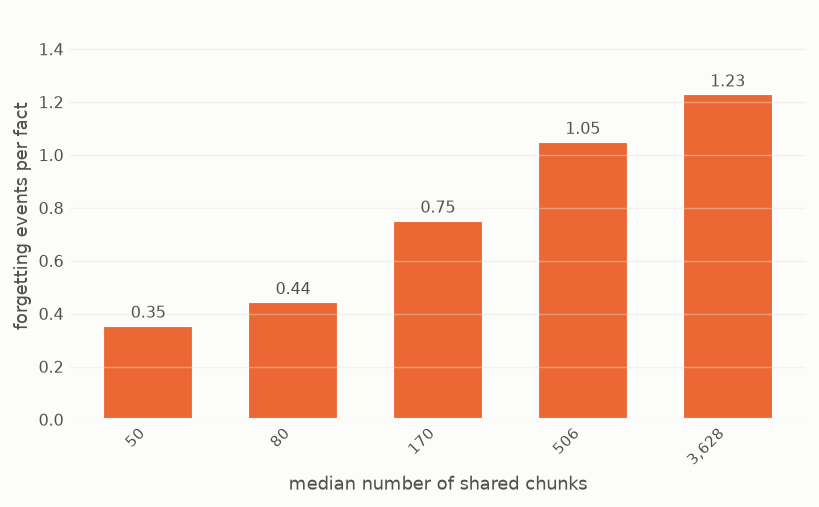

Spearman rho(num_shared_chunks, forgetting count) = +0.380   p = 3.3e-46


In [5]:
tab = by_fact_quintile(evidence)

fig, ax = plt.subplots(figsize=(6.4, 4.0))
x = np.arange(len(tab))
ax.bar(x, tab["events/fact"], 0.62, color=ORANGE, edgecolor=SURF, linewidth=1.2)
for i, v in enumerate(tab["events/fact"]):
    ax.text(i, v + .03, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, [f"{m:,.0f}" for m in tab["median freq"]], rotation=45, ha="right", fontsize=8.5)
ax.set_xlabel("median number of shared chunks")
ax.set_ylabel("forgetting events per fact")
ax.set_ylim(0, tab["events/fact"].max() * 1.25)
clean(ax)
fig.tight_layout(); plt.show()

rho, p = spearmanr(evidence, forgot.sum(1))
print(f"Spearman rho(num_shared_chunks, forgetting count) = {rho:+.3f}   p = {p:.1e}")

---
## 3 — The correction: events rise 3.5×, but opportunities rise 12×

That count is not normalised. Put the number of checkpoints at which each fact is **correct at
all** next to it and the artefact is immediate: rare facts are almost never correct, so they can
barely ever be *observed* to forget. Dividing events by opportunities reverses the sign.

**First figure — both rise, but the denominator rises much faster.** Blue is the mean number of
checkpoints per fact at which the fact is correct (the opportunities to forget); orange is the
forgetting count from §2. Across quintiles the count rises 3.5× while opportunity rises 12.4×.
Both per-fact counts are capped at 12: the panel holds 13 checkpoints, so each fact contributes
13 − 1 = 12 consecutive transitions.

**Second figure — normalised by opportunity, evidence is strongly protective.** The hazard —
events ÷ opportunities within each bin — falls from 56 % to 16 %, crossing the 24 % overall rate
(dashed) between the third and fourth quintile.

Bins are the same construction as §2, so the tick spacing is again not linear.

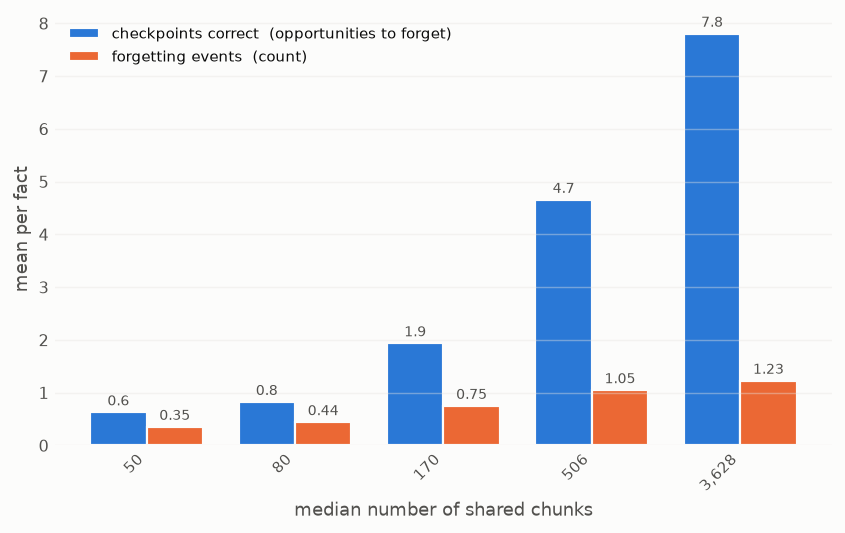

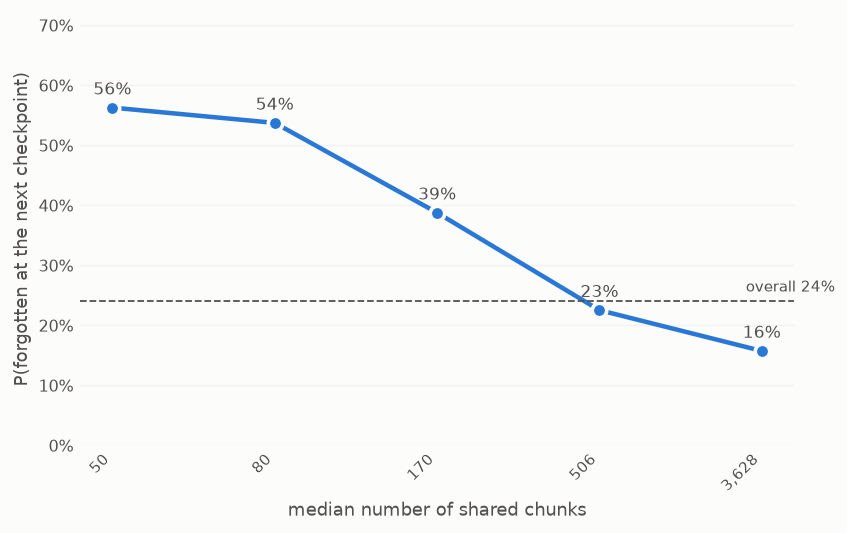

 quintile median freq  facts events/fact correct ckpts/fact hazard
        1          50    265        0.35               0.63  56.3%
        2          80    259        0.44               0.83  53.7%
        3         170    262        0.75               1.94  38.8%
        4         506    262        1.05               4.66  22.5%
        5       3,628    262        1.23               7.81  15.7%

events      x3.5 across quintiles
opportunity x12.4 across quintiles


In [6]:
fig, ax1 = plt.subplots(figsize=(6.6, 4.2))
w = 0.38

ax1.bar(x - w/2, tab["correct ckpts/fact"], w, color=BLUE, edgecolor=SURF, linewidth=1.2,
        label="checkpoints correct  (opportunities to forget)")
ax1.bar(x + w/2, tab["events/fact"], w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label="forgetting events  (count)")
for i in range(len(tab)):
    ax1.text(i - w/2, tab["correct ckpts/fact"][i] + .13, f"{tab['correct ckpts/fact'][i]:.1f}",
             ha="center", fontsize=8, color=INK2)
    ax1.text(i + w/2, tab["events/fact"][i] + .13, f"{tab['events/fact'][i]:.2f}",
             ha="center", fontsize=8, color=INK2)
ax1.set_ylabel("mean per fact")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.set_xticks(x, [f"{m:,.0f}" for m in tab["median freq"]], rotation=45, ha="right", fontsize=8.5)
ax1.set_xlabel("median number of shared chunks")
clean(ax1)
fig.tight_layout(); plt.show()

fig, ax2 = plt.subplots(figsize=(6.6, 4.2))

ax2.plot(x, tab["hazard"], color=BLUE, lw=2.5, marker="o", ms=8,
         mfc=BLUE, mec=SURF, mew=2)
for i, h in enumerate(tab["hazard"]):
    ax2.text(i, h + .022, f"{h:.0%}", ha="center", fontsize=9.5, color=INK2)
ax2.axhline(BASE, color=INK2, ls="--", lw=1)
ax2.text(len(tab) - .55, BASE + .015, f"overall {BASE:.0%}", ha="right", fontsize=8.5, color=INK2)
ax2.set_ylim(0, tab["hazard"].max() * 1.28)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("P(forgotten at the next checkpoint)")
ax2.set_xticks(x, [f"{m:,.0f}" for m in tab["median freq"]], rotation=45, ha="right", fontsize=8.5)
ax2.set_xlabel("median number of shared chunks")
clean(ax2)
fig.tight_layout(); plt.show()

print(tab[["quintile", "median freq", "facts", "events/fact",
           "correct ckpts/fact", "hazard"]].to_string(index=False,
      formatters={"median freq": "{:,.0f}".format, "events/fact": "{:.2f}".format,
                  "correct ckpts/fact": "{:.2f}".format, "hazard": "{:.1%}".format}))
print(f"\nevents      x{tab['events/fact'].iloc[-1] / tab['events/fact'].iloc[0]:.1f} across quintiles")
print(f"opportunity x{tab['correct ckpts/fact'].iloc[-1] / tab['correct ckpts/fact'].iloc[0]:.1f} across quintiles")